# Installing required libraries

In [40]:
!pip install -q sentence-transformers transformers sentencepiece torch pandas matplotlib numpy


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


# Imports and settings

In [41]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sentence_transformers import SentenceTransformer

LLM_MODEL = "google/flan-t5-base"        # google/flan-t5-base  = small and fast

TOP_K = 2                                # how many chunks to retrieve per question
CHUNK_SIZES = [100, 250, 500, 1000]      # chunk sizes (in characters) to compare
print("Settings ready")

Settings ready


In [42]:
# Here we use 2 small sample docs. Later, replace these with your real company documentation.
documents = {
    "hr_policy": """
Every full-time employee gets 24 days of paid annual leave per year. Leave requests must be submitted two weeks in advance.
Employees get 12 days of sick leave per year. A medical certificate is required if sick leave is more than 3 consecutive days.
Employees can work from home up to 2 days per week with manager approval.
The notice period for resignation is 60 days. New employees have a probation period of 6 months.
Expenses must be submitted within 30 days using the ExpenseHub tool.
""",
    "product_faq": """
The Starter plan costs $29 per month and supports up to 5 users. The Pro plan costs $99 per month and supports up to 25 users.
The Enterprise plan has custom pricing and unlimited users.
The public API has a rate limit of 100 requests per minute. Extra requests get an HTTP 429 error.
Acme Insight offers an uptime SLA of 99.9 percent on Pro and Enterprise plans.
Support is available Monday to Friday, 9am to 6pm IST through chat and email.
"""
}
print("Documents loaded:", list(documents.keys()))

Documents loaded: ['hr_policy', 'product_faq']


# Chunking function

In [43]:
# CHUNKING: cut each document into smaller pieces (chunks)

def make_chunks(text, chunk_size):
    text = " ".join(text.split())  
    return [text[i:i + chunk_size] for i in range(0, len(text), chunk_size)]

for size in CHUNK_SIZES:
    print("chunk size", size, "->", len(make_chunks(documents["hr_policy"], size)), "chunks")

chunk size 100 -> 5 chunks
chunk size 250 -> 2 chunks
chunk size 500 -> 1 chunks
chunk size 1000 -> 1 chunks


# Embedding model

In [44]:
# EMBEDDINGS: convert text into a list of numbers that capture its meaning.

embedder = SentenceTransformer("all-MiniLM-L6-v2")
print("Embedding model ready")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Embedding model ready


# Building the search index

In [45]:
# Chunk every document, then convert each chunk into embeddings

def build_index(chunk_size):
    chunks = [{"source": name, "text": c}
              for name, text in documents.items()
              for c in make_chunks(text, chunk_size)]
    embeddings = embedder.encode([c["text"] for c in chunks], normalize_embeddings=True)
    return {"chunks": chunks, "embeddings": embeddings}

index = build_index(250)   # try it with chunk size 250
print("Number of chunks in index:", len(index["chunks"]))

Number of chunks in index: 4


# Retrieval function

In [46]:
# RETRIEVAL FUNCTION: finds the chunks most similar to the question

def retrieve(index, question, k=TOP_K):
    # convert the question to numbers using the same model
    q_emb = embedder.encode([question], normalize_embeddings=True)[0]
    # similarity score of the question with every chunk
    scores = index["embeddings"] @ q_emb
    # pick the k chunks with highest scores
    top_ids = np.argsort(scores)[::-1][:k]
    return [index["chunks"][i] for i in top_ids]

# Tests it
results = retrieve(index, "How many days of annual leave?")
for r in results:
    print("-", r["text"])

- Every full-time employee gets 24 days of paid annual leave per year. Leave requests must be submitted two weeks in advance. Employees get 12 days of sick leave per year. A medical certificate is required if sick leave is more than 3 consecutive days.
-  Employees can work from home up to 2 days per week with manager approval. The notice period for resignation is 60 days. New employees have a probation period of 6 months. Expenses must be submitted within 30 days using the ExpenseHub tool.


# LLM answer function (the full RAG)

In [47]:
from transformers import pipeline

generator = pipeline("text-generation", model="Qwen/Qwen2.5-0.5B-Instruct")

def ask(index, question):
    chunks = retrieve(index, question)
    context = " ".join(c["text"] for c in chunks)
    prompt = f"Answer the question in one short sentence using only the context.\n\nContext: {context}\n\nQuestion: {question}"

    messages = [{"role": "user", "content": prompt}]       # chat format
    output = generator(messages, max_new_tokens=60)
    answer = output[0]["generated_text"][-1]["content"].strip()   # last message = the model's reply

    return answer, chunks

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

In [48]:
answer, chunks = ask(index, "How many days of annual leave do employees get?")
print("ANSWER:", answer)

ANSWER: Employees get 24 days of annual leave per year.


# Test Questions

In [49]:
# Questions to test the system.

test_questions = [
    {"q": "How many days of annual leave do employees get?", "keyword": "24"},
    {"q": "When is a medical certificate needed?",           "keyword": "3 consecutive days"},
    {"q": "How many days can I work from home?",            "keyword": "2 days"},
    {"q": "What is the notice period?",                     "keyword": "60 days"},
    {"q": "What tool is used for expenses?",                "keyword": "ExpenseHub"},
    {"q": "How much does the Pro plan cost?",               "keyword": "$99"},
    {"q": "What is the API rate limit?",                    "keyword": "100 requests"},
    {"q": "What is the uptime SLA?",                        "keyword": "99.9"},
]
print(len(test_questions), "test questions ready")

8 test questions ready


# Running the chunk size experiment

In [50]:
# Repeat the whole RAG process for every chunk size and record the results.
rows = []

for size in CHUNK_SIZES:
    index = build_index(size)               # build index for this chunk size

    for item in test_questions:
        answer, chunks = ask(index, item["q"])
        retrieved_text = " ".join(c["text"] for c in chunks).lower()

        rows.append({
            "chunk_size": size,
            "question": item["q"],
            "answer": answer,
            # did retrieval find the right fact? (1 = yes, 0 = no)
            "retrieval_correct": int(item["keyword"].lower() in retrieved_text),
            # does the final answer contain the right fact?
            "answer_correct": int(item["keyword"].lower() in answer.lower()),
            # how much text we sent to the LLM (more text = more cost)
            "context_length": len(retrieved_text),
        })
    print("finished chunk size", size)

evaluation_table = pd.DataFrame(rows)
evaluation_table.to_csv("response_evaluation_table.csv", index=False)   # DELIVERABLE: Response Evaluation Table
evaluation_table.head(10)

finished chunk size 100
finished chunk size 250
finished chunk size 500
finished chunk size 1000


,chunk_size,question,answer,retrieval_correct,answer_correct,context_length
0,100,How many days of annual leave do employees get?,Employees get 24 days of annual leave per year.,1,1,201
1,100,When is a medical certificate needed?,A medical certificate is required for 6 months...,0,0,191
2,100,How many days can I work from home?,Based on the information provided:\n\n- Red if...,1,1,201
3,100,What is the notice period?,The notice period for resigning from work is 6...,1,1,201
4,100,What tool is used for expenses?,The expense management tool used for expenses ...,1,1,191
5,100,How much does the Pro plan cost?,The Pro plan costs $99 per month and supports ...,1,1,201
6,100,What is the API rate limit?,The API rate limit for Acme Insight of d is 25...,1,0,201
7,100,What is the uptime SLA?,The uptime SLA for Pro and Enterprise plans is...,1,1,142
8,250,How many days of annual leave do employees get?,Employees get 24 days of annual leave per year.,1,1,491
9,250,When is a medical certificate needed?,A medical certificate is required when sick le...,1,1,491


# Comparison summary

In [51]:
summary = evaluation_table.groupby("chunk_size")[["retrieval_correct", "answer_correct", "context_length"]].mean().round(2)
print(summary)

# Best chunk size = highest answer accuracy 
best = summary.sort_values(["answer_correct", "context_length"], ascending=[False, True]).index[0]
print("\nBEST CHUNK SIZE:", best)

summary.to_csv("chunk_size_summary.csv")

            retrieval_correct  answer_correct  context_length
chunk_size                                                   
100                      0.88            0.75          191.12
250                      1.00            1.00          471.38
500                      1.00            0.88          932.00
1000                     1.00            0.75          932.00

BEST CHUNK SIZE: 250


# Vizualization Chart

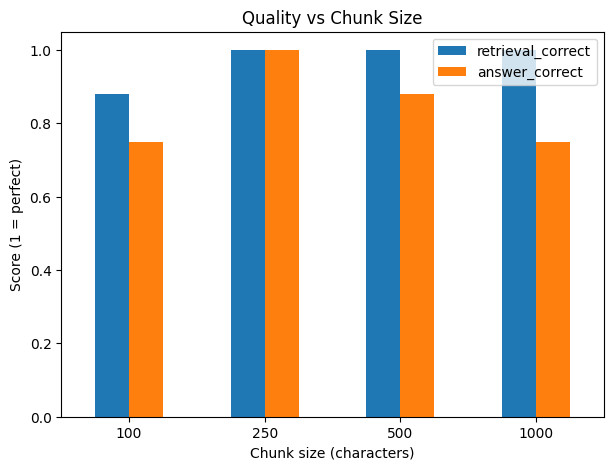

In [52]:
# Visual comparison of chunk sizes
summary[["retrieval_correct", "answer_correct"]].plot(kind="bar", figsize=(7, 5))
plt.title("Quality vs Chunk Size")
plt.xlabel("Chunk size (characters)")
plt.ylabel("Score (1 = perfect)")
plt.xticks(rotation=0)
plt.savefig("chunk_size_chart.png")
plt.show()

# Comparison report

In [53]:
report = f""" RAG Chunk Size Comparison Report

Setup:
- Embedding model: all-MiniLM-L6-v2 (free, local)
- LLM: {LLM_MODEL} (free, local)
- Chunk sizes tested: {CHUNK_SIZES}
- Retrieved chunks per question (top-k): {TOP_K}
- Number of test questions: {len(test_questions)}

Results:
{summary.to_string()}

Best chunk size:
{best} characters

Findings:
- Small chunks: precise, but a fact can get split across chunks and be missed.
- Large chunks: contain more information, but add noise and slow down the LLM.
- The best size is the one with the highest answer accuracy and the smallest context.
"""
with open("comparison_report.md", "w") as f:
    f.write(report)
print(report)

 RAG Chunk Size Comparison Report

Setup:
- Embedding model: all-MiniLM-L6-v2 (free, local)
- LLM: google/flan-t5-base (free, local)
- Chunk sizes tested: [100, 250, 500, 1000]
- Retrieved chunks per question (top-k): 2
- Number of test questions: 8

Results:
            retrieval_correct  answer_correct  context_length
chunk_size                                                   
100                      0.88            0.75          191.12
250                      1.00            1.00          471.38
500                      1.00            0.88          932.00
1000                     1.00            0.75          932.00

Best chunk size:
250 characters

Findings:
- Small chunks: precise, but a fact can get split across chunks and be missed.
- Large chunks: contain more information, but add noise and slow down the LLM.
- The best size is the one with the highest answer accuracy and the smallest context.



### **Performance Results:**

* **100-character chunks:** Achieved an 88% retrieval accuracy and 75% answer accuracy with an average context length of 191.12 characters.


* **250-character chunks:** Achieved a 100% retrieval accuracy and a top-performing 100% answer accuracy with an average context length of 471.38 characters.


* **500-character chunks:** Achieved a 100% retrieval accuracy and an 88% answer accuracy with an average context length of 932.00 characters.


* **1000-character chunks:** Achieved a 100% retrieval accuracy and a 75% answer accuracy with an average context length of 932.00 characters.



**Best Chunk Size:** The **250-character** size was identified as the best option because it delivered the highest overall answer accuracy (100%) while keeping the context length compact.

**Key Findings:** Small chunks (100 characters) can be too precise and split facts across boundaries, while overly large chunks (1000 characters) add unnecessary context noise that degrades the LLM's final response accuracy. The 250-character size provided the optimal balance.